<a href="https://colab.research.google.com/github/pranavp317/CoinTrace-Bitcoin-Transaction-Pattern-Clustering-/blob/main/cointrace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, random, glob
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # must be set before any GPU work
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

In [ ]:
path = kagglehub.dataset_download("ellipticco/elliptic-data-set")
print("Downloaded to:", path)

for f in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True):
    print(f, "-", round(os.path.getsize(f) / 1e6, 1), "MB")

Using Colab cache for faster access to the 'elliptic-data-set' dataset.
Downloaded to: /kaggle/input/elliptic-data-set
/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_features.csv - 689.7 MB
/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_classes.csv - 3.3 MB
/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv - 4.5 MB


In [ ]:
def find(name):
    return glob.glob(os.path.join(path, "**", name), recursive=True)[0]

# The features file has NO header row, so we name the columns ourselves
feat_cols = ["txId", "time_step"] + [f"f{i}" for i in range(1, 166)]
features = pd.read_csv(find("elliptic_txs_features.csv"), header=None, names=feat_cols)

# Read labels as strings because the column mixes '1', '2' and 'unknown'
classes = pd.read_csv(find("elliptic_txs_classes.csv"), dtype=str)
edges = pd.read_csv(find("elliptic_txs_edgelist.csv"))

# Original encoding: '1' = illicit, '2' = licit
label_map = {"1": 1, "2": 0, "unknown": -1}
classes["label"] = classes["class"].map(label_map)
classes["label_name"] = classes["label"].map({1: "illicit", 0: "licit", -1: "unknown"})

classes["txId"] = classes["txId"].astype(features["txId"].dtype)
df = features.merge(classes[["txId", "label", "label_name"]], on="txId", how="left")

print("features:", features.shape, "| classes:", classes.shape, "| edges:", edges.shape)
df.head()

features: (203769, 167) | classes: (203769, 4) | edges: (234355, 2)


,txId,time_step,f1,f2,f3,f4,f5,f6,f7,f8,...,f158,f159,f160,f161,f162,f163,f164,f165,label,label_name
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,-1,unknown
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,-1,unknown
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,-1,unknown
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0,licit
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,-1,unknown


Shape: (203769, 169)
Total nulls: 0
Duplicate txIds: 0
Time steps: 1 to 49

              count  percent
label_name                 
unknown     157205    77.15
licit        42019    20.62
illicit       4545     2.23
label_name  illicit  licit  unknown
time_step                          
1                17   2130     5733
2                18   1099     3427
3                11   1268     5342
4                30   1410     4253
5                 8   1874     4921


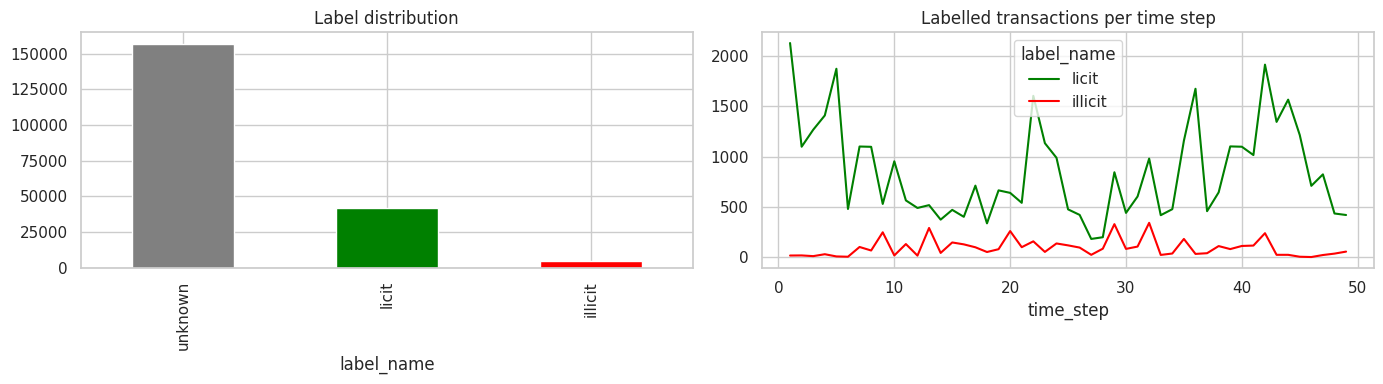

Edges with unknown endpoint: 0


In [ ]:
# Shape, types, missing values
print("Shape:", df.shape)
print("Total nulls:", df.isnull().sum().sum())
print("Duplicate txIds:", df["txId"].duplicated().sum())
print("Time steps:", df["time_step"].min(), "to", df["time_step"].max())

# Label distribution
dist = df["label_name"].value_counts()
print("\n", pd.concat([dist, (dist / len(df) * 100).round(2)], axis=1,
                      keys=["count", "percent"]))

# Counts per time step
per_step = df.groupby(["time_step", "label_name"]).size().unstack(fill_value=0)
print(per_step.head())

# Plots
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
dist.plot(kind="bar", ax=ax[0], color=["gray", "green", "red"])
ax[0].set_title("Label distribution")
per_step[["licit", "illicit"]].plot(ax=ax[1], color=["green", "red"])
ax[1].set_title("Labelled transactions per time step")
plt.tight_layout()
plt.show()

# Edge sanity check: do all edge endpoints exist as nodes?
edges.columns = ["src", "dst"]
ids = set(df["txId"])
print("Edges with unknown endpoint:", (~edges["src"].isin(ids) | ~edges["dst"].isin(ids)).sum())

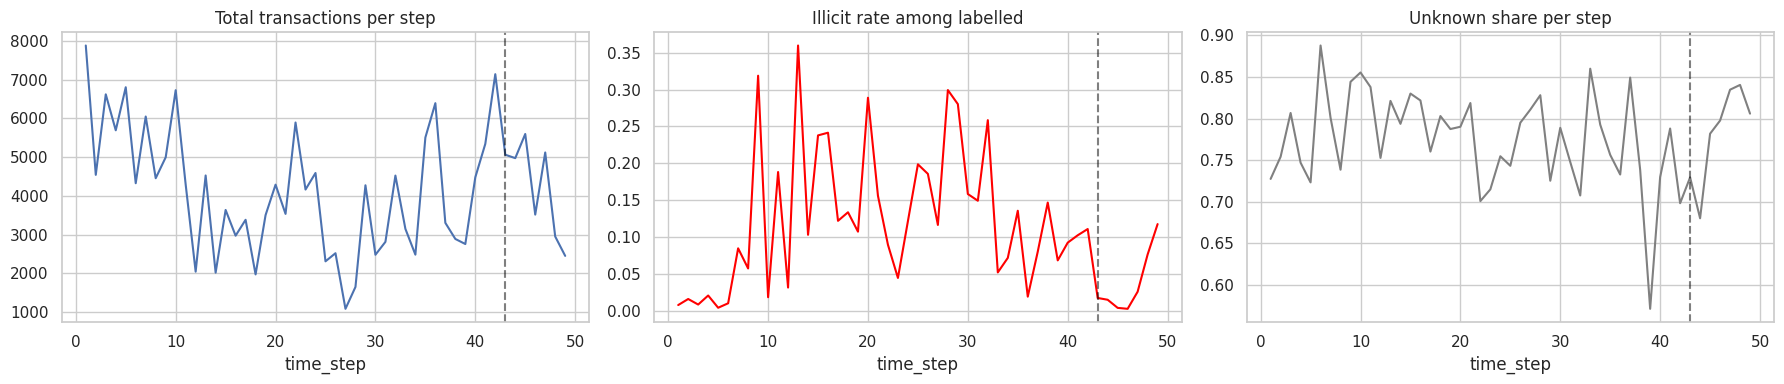

           total  illicit  licit  illicit_rate_labelled
time_step                                              
40          4481      112   1099                  0.092
41          5342      116   1016                  0.102
42          7140      239   1915                  0.111
43          5063       24   1346                  0.018
44          4975       24   1567                  0.015
45          5598        5   1216                  0.004
46          3519        2    710                  0.003
47          5121       22    824                  0.026
48          2954       36    435                  0.076
49          2454       56    420                  0.118


In [ ]:
labelled = df[df["label"] != -1]

step = df.groupby("time_step").agg(
    total=("txId", "size"),
    illicit=("label", lambda s: (s == 1).sum()),
    licit=("label", lambda s: (s == 0).sum()),
    unknown=("label", lambda s: (s == -1).sum()),
)
step["illicit_rate_labelled"] = step["illicit"] / (step["illicit"] + step["licit"])
step["unknown_share"] = step["unknown"] / step["total"]

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
step["total"].plot(ax=ax[0]); ax[0].set_title("Total transactions per step")
step["illicit_rate_labelled"].plot(ax=ax[1], color="red")
ax[1].set_title("Illicit rate among labelled")
step["unknown_share"].plot(ax=ax[2], color="gray"); ax[2].set_title("Unknown share per step")
for a in ax: a.axvline(43, ls="--", color="black", alpha=.5)
plt.tight_layout(); plt.show()

print(step.loc[40:49, ["total", "illicit", "licit", "illicit_rate_labelled"]].round(3))

label_name          illicit     licit
in_degree    count  4545.00  42019.00
             mean      1.27      1.91
             std       7.22      7.12
             min       0.00      0.00
             25%       0.00      0.00
             50%       1.00      1.00
             75%       1.00      1.00
             max     177.00    284.00
out_degree   count  4545.00  42019.00
             mean      0.74      1.19
             std       0.57      3.25
             min       0.00      0.00
             25%       0.00      1.00
             50%       1.00      1.00
             75%       1.00      1.00
             max       3.00    472.00
total_degree count  4545.00  42019.00
             mean      2.01      3.10
             std       7.18      7.78
             min       1.00      1.00
             25%       1.00      1.00
             50%       1.00      2.00
             75%       2.00      3.00
             max     177.00    473.00


/tmp/ipykernel_1545/3436321863.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=lab, x="label_name", y=col, ax=a,
/tmp/ipykernel_1545/3436321863.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=lab, x="label_name", y=col, ax=a,
/tmp/ipykernel_1545/3436321863.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=lab, x="label_name", y=col, ax=a,


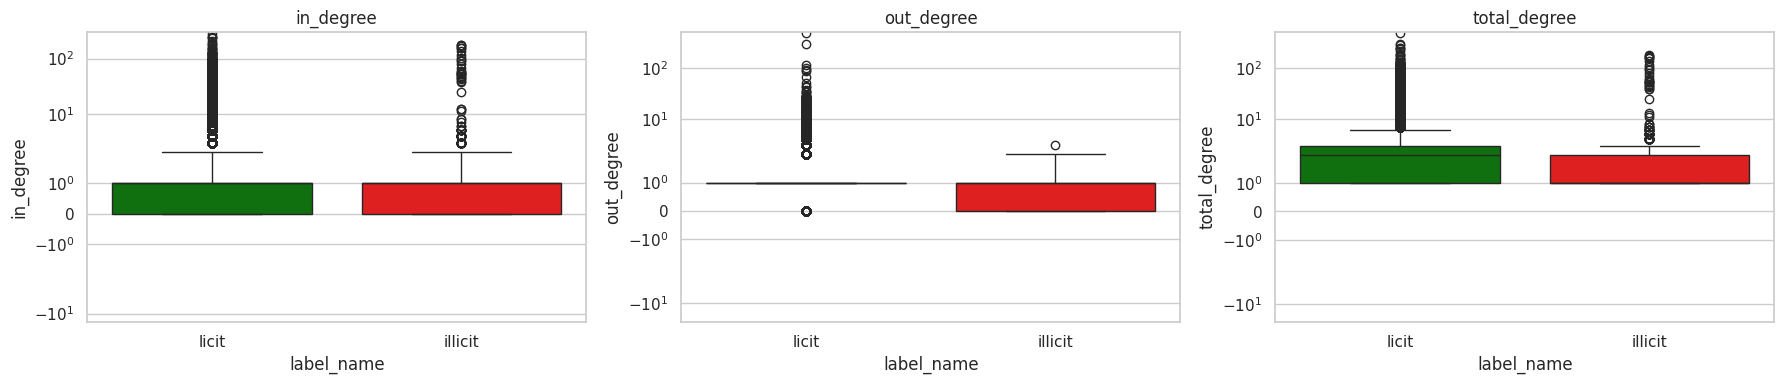

Isolated nodes (degree 0): 0


In [ ]:
# Directed degree from the edge list
out_deg = edges["src"].value_counts()
in_deg = edges["dst"].value_counts()

df["out_degree"] = df["txId"].map(out_deg).fillna(0).astype(int)
df["in_degree"] = df["txId"].map(in_deg).fillna(0).astype(int)
df["total_degree"] = df["in_degree"] + df["out_degree"]

lab = df[df["label"] != -1]
print(lab.groupby("label_name")[["in_degree", "out_degree", "total_degree"]]
        .describe().T.round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, col in zip(ax, ["in_degree", "out_degree", "total_degree"]):
    sns.boxplot(data=lab, x="label_name", y=col, ax=a,
                order=["licit", "illicit"], palette=["green", "red"])
    a.set_yscale("symlog"); a.set_title(col)
plt.tight_layout(); plt.show()

print("Isolated nodes (degree 0):", (df["total_degree"] == 0).sum())

c7

Near-constant features (var < 1e-3): 0
Highly skewed (|skew| > 5): 87
Feature pairs with |corr| > 0.95: 103
Features droppable at 0.95: 66

Mean |effect size| local: 0.226
Mean |effect size| aggregated: 0.158

Top 10 separating features:
 f53     0.88
f89     0.77
f55     0.77
f90     0.75
f142    0.65
f150    0.63
f91     0.63
f52     0.58
f154    0.52
f54     0.48
dtype: float64


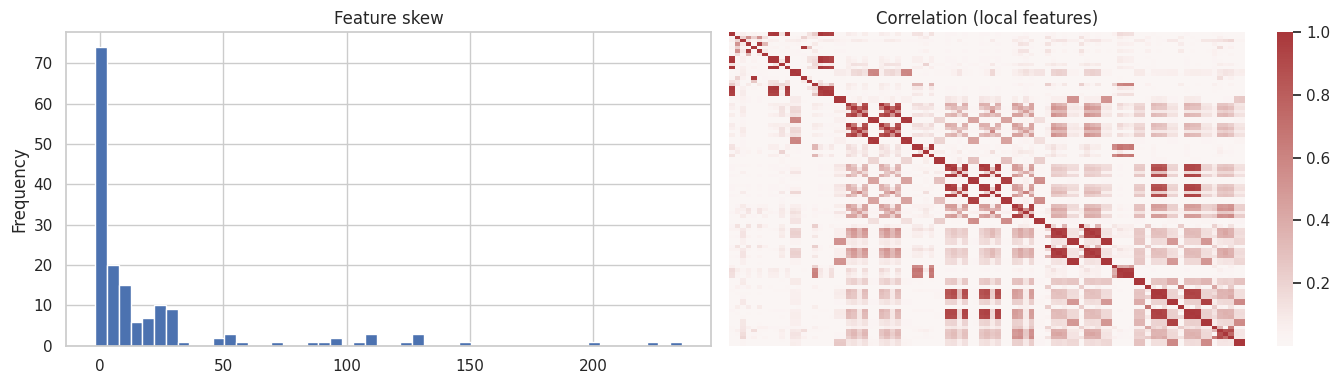

In [ ]:
local_cols = [f"f{i}" for i in range(1, 94)]        # transaction's own properties
agg_cols = [f"f{i}" for i in range(94, 166)]        # neighbour aggregates
all_feats = local_cols + agg_cols

# 1) Variance and skew
stats = pd.DataFrame({"var": df[all_feats].var(), "skew": df[all_feats].skew()})
print("Near-constant features (var < 1e-3):", (stats["var"] < 1e-3).sum())
print("Highly skewed (|skew| > 5):", (stats["skew"].abs() > 5).sum())

# 2) Redundancy: highly correlated pairs (sample for speed)
sample = df[all_feats].sample(50000, random_state=SEED)
corr = sample.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Feature pairs with |corr| > 0.95:", (upper > 0.95).sum().sum())
print("Features droppable at 0.95:", (upper > 0.95).any().sum())

# 3) Which feature group separates illicit from licit? (exploration only)
il = lab[lab["label"] == 1][all_feats]; li = lab[lab["label"] == 0][all_feats]
effect = ((il.mean() - li.mean()) / lab[all_feats].std()).abs()
print("\nMean |effect size| local:", effect[local_cols].mean().round(3))
print("Mean |effect size| aggregated:", effect[agg_cols].mean().round(3))
print("\nTop 10 separating features:\n", effect.sort_values(ascending=False).head(10).round(2))

# Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
stats["skew"].plot(kind="hist", bins=50, ax=ax[0]); ax[0].set_title("Feature skew")
sns.heatmap(corr.iloc[:93, :93], ax=ax[1], cmap="vlag", center=0, xticklabels=False, yticklabels=False)
ax[1].set_title("Correlation (local features)")
plt.tight_layout(); plt.show()

c8

In [ ]:
from scipy.stats import skew
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, RobustScaler,
                                   QuantileTransformer, FunctionTransformer)

local_cols = [f"f{i}" for i in range(1, 94)]
agg_cols   = [f"f{i}" for i in range(94, 166)]
all_cols   = local_cols + agg_cols

TRAIN_MAX_STEP = 34                      # fit on steps 1-34, apply to 35-49
train_mask = (df["time_step"] <= TRAIN_MAX_STEP).values
lab_mask   = (df["label"] != -1).values
print("Train rows:", train_mask.sum(), "| later rows:", (~train_mask).sum())

# Are the raw features already centred / scaled?
raw = df[all_cols]
print("max |mean|:", round(raw.mean().abs().max(), 3),
      "| std range:", round(raw.std().min(), 3), "to", round(raw.std().max(), 3))


def _signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

def _clip(X, lim=5.0):
    return np.clip(X, -lim, lim)

def make_preprocessor(method="slog_std"):
    if method == "slog_std":
        steps = [("slog", FunctionTransformer(_signed_log)),
                 ("scale", StandardScaler()),
                 ("clip", FunctionTransformer(_clip))]
    elif method == "robust":
        steps = [("scale", RobustScaler()),
                 ("clip", FunctionTransformer(_clip))]
    elif method == "quantile":
        steps = [("q", QuantileTransformer(output_distribution="normal",
                                           n_quantiles=1000, subsample=100_000,
                                           random_state=SEED))]
    else:
        raise ValueError(method)
    return Pipeline(steps)

def preprocess(cols, method="slog_std", fit_mask=train_mask):
    """Fit on fit_mask rows only, transform ALL rows. Returns float32 array aligned with df."""
    X = df[cols].to_numpy(dtype=np.float32)
    prep = make_preprocessor(method).fit(X[fit_mask])
    return prep.transform(X).astype(np.float32), prep


# Compare methods on the skew problem
raw_skew = pd.Series(skew(df.loc[train_mask, all_cols].to_numpy(), axis=0), index=all_cols).abs()
rows = [{"method": "raw", "features |skew|>5": int((raw_skew > 5).sum()),
         "median |skew|": round(raw_skew.median(), 2)}]
for m in ["robust", "slog_std", "quantile"]:
    Xm, _ = preprocess(all_cols, m)
    s = pd.Series(skew(Xm[train_mask], axis=0), index=all_cols).abs()
    rows.append({"method": m, "features |skew|>5": int((s > 5).sum()),
                 "median |skew|": round(s.median(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

X_slog, _ = preprocess(all_cols, "slog_std")
print("Share of values clipped at +/-5 (slog_std):", round(float((np.abs(X_slog) >= 5).mean()), 4))

Train rows: 136265 | later rows: 67504
max |mean|: 0.0 | std range: 1.0 to 1.0
  method  features |skew|>5  median |skew|
     raw                 85           6.33
  robust                 21           1.38
slog_std                 38           3.11
quantile                  3           0.31
Share of values clipped at +/-5 (slog_std): 0.0061


c9

In [ ]:
import networkx as nx

# 0) Sanity check: do edges stay inside one time step?
ts = df.set_index("txId")["time_step"]
same_step = (edges["src"].map(ts).values == edges["dst"].map(ts).values)
print("Share of edges inside a single time step:", round(same_step.mean(), 4))

# 1) PageRank, computed separately inside each time step
edges_ts = edges.assign(step=edges["src"].map(ts).values)
pr = {}
for s, e in edges_ts.groupby("step"):
    G = nx.from_pandas_edgelist(e, "src", "dst", create_using=nx.DiGraph)
    p = nx.pagerank(G, alpha=0.85, max_iter=200)
    n = G.number_of_nodes()
    pr.update({k: v * n for k, v in p.items()})   # 1.0 = average importance within its step
df["pagerank"] = df["txId"].map(pr).fillna(0.0)

# 2) Neighbour degree stats (label-agnostic)
deg = df.set_index("txId")["total_degree"]
e = edges.assign(src_deg=edges["src"].map(deg).values,
                 dst_deg=edges["dst"].map(deg).values)
df["nbr_in_deg_mean"]  = df["txId"].map(e.groupby("dst")["src_deg"].mean()).fillna(0.0)  # avg degree of predecessors
df["nbr_out_deg_mean"] = df["txId"].map(e.groupby("src")["dst_deg"].mean()).fillna(0.0)  # avg degree of successors

# 3) Source / sink flags
df["is_source"] = (df["in_degree"] == 0).astype(int)
df["is_sink"]   = (df["out_degree"] == 0).astype(int)

graph_cols = ["in_degree", "out_degree", "total_degree", "pagerank",
              "nbr_in_deg_mean", "nbr_out_deg_mean", "is_source", "is_sink"]
print(df[graph_cols].describe().T.round(3))

# Just to look (not for feature selection): means by label
print(df[lab_mask].groupby("label_name")[graph_cols].mean().T.round(3))

Share of edges inside a single time step: 1.0
                     count    mean     std   min    25%    50%   75%      max
in_degree         203769.0   1.150   3.911  0.00  0.000  1.000  1.00  284.000
out_degree        203769.0   1.150   1.895  0.00  1.000  1.000  1.00  472.000
total_degree      203769.0   2.300   4.328  1.00  1.000  2.000  2.00  473.000
pagerank          203769.0   1.000   1.796  0.24  0.396  0.648  1.15   99.599
nbr_in_deg_mean   203769.0   4.097  22.030  0.00  0.000  2.000  3.00  473.000
nbr_out_deg_mean  203769.0  12.242  27.421  0.00  1.500  2.000  7.00  284.000
is_source         203769.0   0.271   0.445  0.00  0.000  0.000  1.00    1.000
is_sink           203769.0   0.184   0.387  0.00  0.000  0.000  0.00    1.000
label_name        illicit   licit
in_degree           1.270   1.909
out_degree          0.742   1.186
total_degree        2.012   3.095
pagerank            0.844   1.154
nbr_in_deg_mean     2.488  10.903
nbr_out_deg_mean   16.212  11.457
is_source     

c10

      feature_set  n_features  PCs@90%  PCs@95%  PCs@99%
          A_local          93       17       22       34
      B_local+agg         165       37       47       68
C_local+agg+graph         173       40       51       74


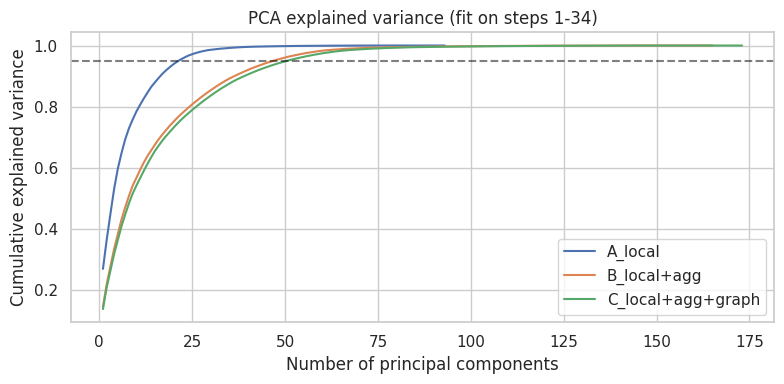

In [ ]:
from sklearn.decomposition import PCA

FEATURE_SETS = {
    "A_local":           local_cols,
    "B_local+agg":       all_cols,
    "C_local+agg+graph": all_cols + graph_cols,
}

X_scaled, X_pca, cum_var, rows = {}, {}, {}, []
for name, cols in FEATURE_SETS.items():
    Xs, _ = preprocess(cols, "slog_std")
    pca = PCA(svd_solver="full", random_state=SEED).fit(Xs[train_mask])
    cum = np.cumsum(pca.explained_variance_ratio_)
    k90, k95, k99 = (int(np.searchsorted(cum, t)) + 1 for t in (0.90, 0.95, 0.99))
    X_scaled[name] = Xs
    X_pca[name] = pca.transform(Xs)[:, :k95].astype(np.float32)
    cum_var[name] = cum
    rows.append({"feature_set": name, "n_features": len(cols),
                 "PCs@90%": k90, "PCs@95%": k95, "PCs@99%": k99})
print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(8, 4))
for name, cum in cum_var.items():
    plt.plot(np.arange(1, len(cum) + 1), cum, label=name)
plt.axhline(0.95, ls="--", color="black", alpha=.5)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (fit on steps 1-34)")
plt.legend(); plt.tight_layout(); plt.show()

c10

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


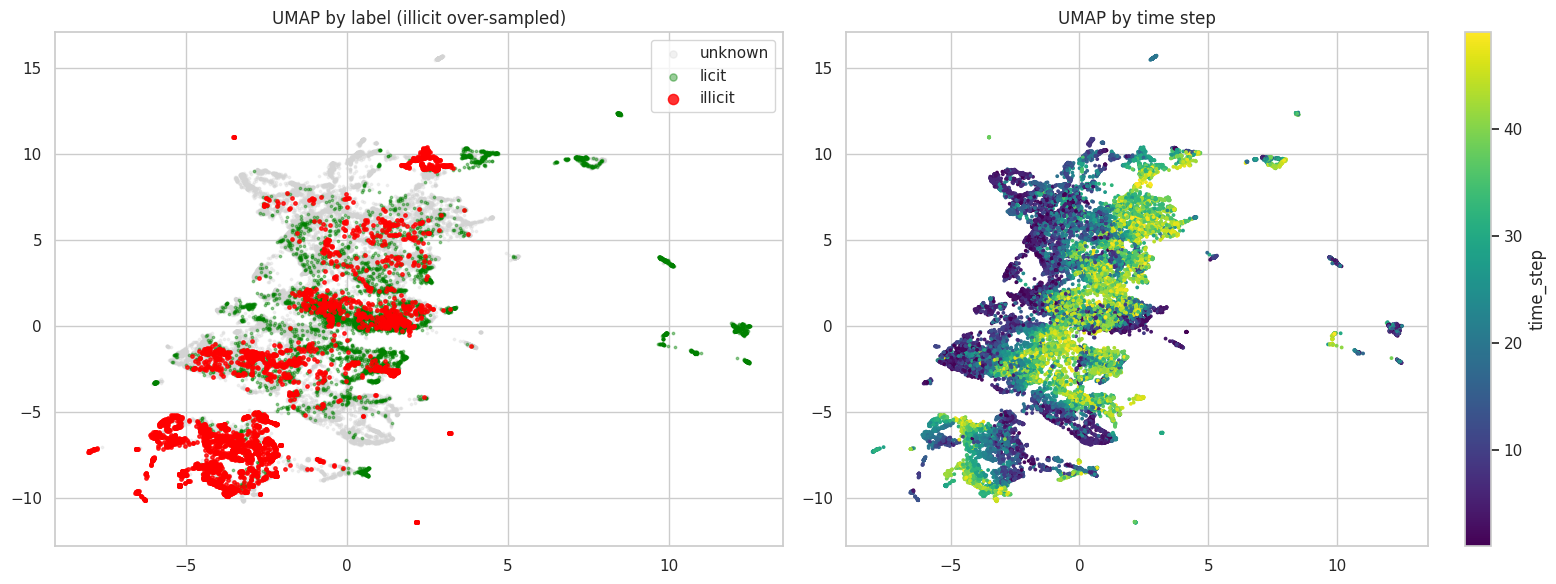

In [ ]:
!pip install -q umap-learn
import umap

rng = np.random.default_rng(SEED)
illicit_idx = np.where(df["label"].values == 1)[0]
other_idx   = np.where(df["label"].values != 1)[0]
viz_idx = np.concatenate([illicit_idx, rng.choice(other_idx, 30000, replace=False)])

emb = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(
    X_pca["B_local+agg"][viz_idx])

v = df.iloc[viz_idx]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, color, s, a in [("unknown", "lightgray", 3, .3),
                          ("licit", "green", 3, .4),
                          ("illicit", "red", 6, .8)]:
    m = (v["label_name"] == name).values
    ax[0].scatter(emb[m, 0], emb[m, 1], c=color, s=s, alpha=a, label=name)
ax[0].legend(markerscale=3)
ax[0].set_title("UMAP by label (illicit over-sampled)")
sc = ax[1].scatter(emb[:, 0], emb[:, 1], c=v["time_step"], s=3, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="time_step")
ax[1].set_title("UMAP by time step")
plt.tight_layout(); plt.show()

ct11 c12

Clipped share, robust:   0.0661
Clipped share, slog_std: 0.0061


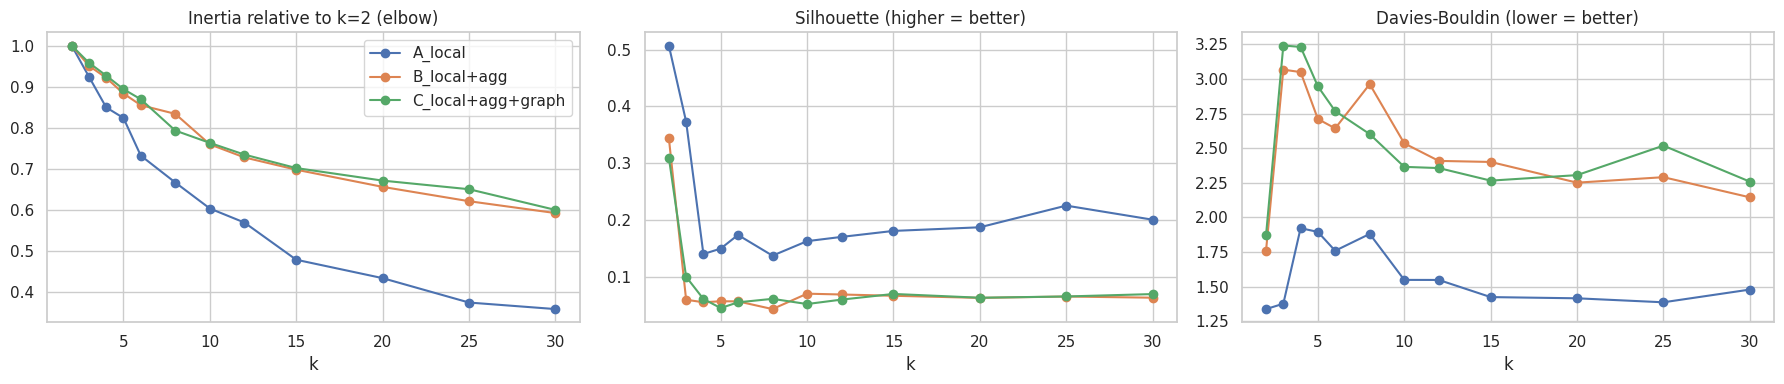

feature_set  A_local  B_local+agg  C_local+agg+graph
k                                                   
2              0.507        0.345              0.310
3              0.373        0.060              0.101
4              0.141        0.056              0.062
5              0.150        0.058              0.046
6              0.174        0.057              0.056
8              0.138        0.044              0.062
10             0.163        0.071              0.053
12             0.171        0.070              0.061
15             0.181        0.067              0.070
20             0.188        0.064              0.064
25             0.226        0.066              0.066
30             0.201        0.064              0.070
feature_set  A_local  B_local+agg  C_local+agg+graph
k                                                   
2              1.338        1.761              1.873
3              1.376        3.068              3.242
4              1.922        3.050             

In [ ]:
from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)

# (a) The number the skew table hid: how much does each option clip?
Xr, _ = preprocess(all_cols, "robust")
print("Clipped share, robust:  ", round(float((np.abs(Xr) >= 5).mean()), 4))
print("Clipped share, slog_std:", round(float((np.abs(X_scaled["B_local+agg"]) >= 5).mean()), 4))
del Xr

# (b) Sweep k on the training period only (steps 1-34)
K_GRID = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]
tr_idx = np.where(train_mask)[0]
sil_idx = np.random.default_rng(SEED).choice(tr_idx, 10_000, replace=False)  # fixed subsample

rows = []
for name in FEATURE_SETS:
    X = X_pca[name]
    for k in K_GRID:
        km = MiniBatchKMeans(n_clusters=k, n_init=5, batch_size=4096,
                             random_state=SEED).fit(X[train_mask])
        lab_s = km.predict(X[sil_idx])
        rows.append({"feature_set": name, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X[sil_idx], lab_s),
                     "davies_bouldin": davies_bouldin_score(X[sil_idx], lab_s),
                     "calinski_harabasz": calinski_harabasz_score(X[sil_idx], lab_s)})
sweep = pd.DataFrame(rows)
sweep["inertia_rel"] = sweep["inertia"] / sweep.groupby("feature_set")["inertia"].transform("first")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, g in sweep.groupby("feature_set"):
    ax[0].plot(g["k"], g["inertia_rel"], marker="o", label=name)
    ax[1].plot(g["k"], g["silhouette"], marker="o", label=name)
    ax[2].plot(g["k"], g["davies_bouldin"], marker="o", label=name)
ax[0].set_title("Inertia relative to k=2 (elbow)")
ax[1].set_title("Silhouette (higher = better)")
ax[2].set_title("Davies-Bouldin (lower = better)")
for a in ax: a.set_xlabel("k")
ax[0].legend(); plt.tight_layout(); plt.show()

print(sweep.pivot(index="k", columns="feature_set", values="silhouette").round(3))
print(sweep.pivot(index="k", columns="feature_set", values="davies_bouldin").round(3))

c13 ct17

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

PERIODS = {"train (1-34)": train_mask, "later (35-49)": ~train_mask}
MIN_LAB, MIN_LIFT = 30, 2.0   # "enriched cluster" thresholds, fixed now before seeing results

def evaluate(cluster_labels, name, show_table=True, top=12):
    """External validation on labelled nodes only; labels never influence the clustering.
    cluster_labels: int array aligned with df. -1 is treated as its own group (noise)."""
    y = df["label"].values
    summary, tables = [], {}
    for pname, pmask in PERIODS.items():
        d = pd.DataFrame({"cluster": cluster_labels[pmask], "label": y[pmask]})
        ct = pd.crosstab(d["cluster"], d["label"]).reindex(columns=[-1, 0, 1], fill_value=0)
        ct.columns = ["n_unknown", "n_licit", "n_illicit"]
        ct["n_total"] = ct.sum(axis=1)
        ct["n_labelled"] = ct["n_licit"] + ct["n_illicit"]
        base = ct["n_illicit"].sum() / ct["n_labelled"].sum()        # illicit rate in this period
        ct["illicit_rate"] = ct["n_illicit"] / ct["n_labelled"].replace(0, np.nan)
        ct["lift"] = ct["illicit_rate"] / base
        tables[pname] = ct

        m = (d["label"] != -1).values
        yy, cc = d.loc[m, "label"].values, d.loc[m, "cluster"].values
        enr = ct[(ct["n_labelled"] >= MIN_LAB) & (ct["lift"] >= MIN_LIFT)]
        summary.append({
            "model": name, "period": pname,
            "n_clusters": int((ct.index != -1).sum()),
            "base_rate": round(base, 4),
            "ARI": round(adjusted_rand_score(yy, cc), 4),
            "NMI": round(normalized_mutual_info_score(yy, cc), 4),
            "purity": round(ct[["n_licit", "n_illicit"]].max(axis=1).sum() / ct["n_labelled"].sum(), 4),
            "purity_1cluster": round(max(base, 1 - base), 4),
            "enriched_k": len(enr),
            "illicit_captured": round(enr["n_illicit"].sum() / ct["n_illicit"].sum(), 3),
            "labelled_covered": round(enr["n_labelled"].sum() / ct["n_labelled"].sum(), 3),
        })
    summary = pd.DataFrame(summary)
    if show_table:
        t = tables["train (1-34)"].sort_values("lift", ascending=False)
        print(t[t["n_labelled"] >= MIN_LAB].head(top).round(3).to_string())
    return summary, tables

c14

In [ ]:
K_CHOSEN = 10      # Chosen from the sweep results (e.g., 10)
assert K_CHOSEN is not None, "Set K_CHOSEN from the sweep first"
DETAIL = "B_local+agg"

km_labels, km_summaries = {}, []
for name in FEATURE_SETS:
    X = X_pca[name]
    km = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=SEED).fit(X[train_mask])
    km_labels[name] = km.predict(X).astype(int)      # fitted on steps 1-34, applied to all rows
    s, _ = evaluate(km_labels[name], f"KMeans-{name}", show_table=False)
    km_summaries.append(s)
km_summary = pd.concat(km_summaries, ignore_index=True)
print(km_summary.to_string(index=False))

print(f"\nTop clusters, {DETAIL} (training period):")
_ = evaluate(km_labels[DETAIL], f"KMeans-{DETAIL}", show_table=True)

# Does the cluster mix shift after step 34? (early drift check for CT-15)
mix = pd.crosstab(km_labels[DETAIL], np.where(train_mask, "train", "later"), normalize="columns")
mix["shift"] = mix["later"] - mix["train"]
print("\nShare of rows per cluster:\n", mix.round(3))

                   model        period  n_clusters  base_rate     ARI    NMI  purity  purity_1cluster  enriched_k  illicit_captured  labelled_covered
          KMeans-A_local  train (1-34)          10     0.1158 -0.0073 0.0736  0.8842           0.8842           2             0.802             0.292
          KMeans-A_local later (35-49)          10     0.0650 -0.0039 0.0400  0.9350           0.9350           1             0.675             0.213
      KMeans-B_local+agg  train (1-34)          10     0.1158  0.0027 0.0556  0.8842           0.8842           1             0.445             0.178
      KMeans-B_local+agg later (35-49)          10     0.0650 -0.0331 0.0356  0.9361           0.9350           0             0.000             0.000
KMeans-C_local+agg+graph  train (1-34)          10     0.1158  0.0060 0.0652  0.8842           0.8842           2             0.564             0.218
KMeans-C_local+agg+graph later (35-49)          10     0.0650 -0.0363 0.0347  0.9361           0.935

c15

In [ ]:
def transfer_test(labels, name):
    """Choose enriched clusters on TRAIN labels only (same thresholds), score them on LATER labels."""
    y = df["label"].values
    tr = train_mask & (y != -1)
    la = (~train_mask) & (y != -1)
    base_tr, base_la = (y[tr] == 1).mean(), (y[la] == 1).mean()

    ct = pd.crosstab(labels[tr], y[tr]).reindex(columns=[0, 1], fill_value=0)
    n = ct.sum(axis=1)
    lift = (ct[1] / n) / base_tr
    chosen = lift[(n >= MIN_LAB) & (lift >= MIN_LIFT)].index.tolist()

    in_c = np.isin(labels, chosen)
    ill_later = (y[la] == 1).sum()
    hit = in_c[la]
    return {"model": name, "chosen_clusters": chosen,
            "later_illicit_captured": round(((y[la] == 1) & hit).sum() / ill_later, 3),
            "later_labelled_covered": round(hit.mean(), 3),
            "later_illicit_rate_in_chosen": round((y[la][hit] == 1).mean(), 3) if hit.any() else np.nan,
            "later_base_rate": round(base_la, 4),
            "later_lift": round((y[la][hit] == 1).mean() / base_la, 2) if hit.any() else np.nan}

print(pd.DataFrame([transfer_test(km_labels[n], f"KMeans-{n}") for n in FEATURE_SETS]).to_string(index=False))

# A_local detail: training table with unknown share, plus cluster-mix shift
_, tabs = evaluate(km_labels["A_local"], "KMeans-A_local", show_table=False)
t = tabs["train (1-34)"].copy()
t["unknown_share"] = t["n_unknown"] / t["n_total"]
print("\nA_local clusters (training period):")
print(t.sort_values("lift", ascending=False).round(3).to_string())

mixA = pd.crosstab(km_labels["A_local"], np.where(train_mask, "train", "later"), normalize="columns")
mixA["shift"] = mixA["later"] - mixA["train"]
print("\nA_local share of rows per cluster:\n", mixA.round(3))

                   model chosen_clusters  later_illicit_captured  later_labelled_covered  later_illicit_rate_in_chosen  later_base_rate  later_lift
          KMeans-A_local          [4, 5]                   0.675                   0.305                         0.144            0.065        2.21
      KMeans-B_local+agg             [9]                   0.829                   0.450                         0.120            0.065        1.84
KMeans-C_local+agg+graph          [2, 8]                   0.836                   0.541                         0.100            0.065        1.54

A_local clusters (training period):
         n_unknown  n_licit  n_illicit  n_total  n_labelled  illicit_rate   lift  unknown_share
cluster                                                                                        
4            21601     4688       2355    28644        7043         0.334  2.887          0.754
5             5533     1252        420     7205        1672         0.251  2.169   

c16

In [ ]:
from sklearn.cluster import HDBSCAN
from sklearn.neighbors import NearestNeighbors
import time

SET = "A_local"
X = X_pca[SET]
rng = np.random.default_rng(SEED)
sub = rng.choice(np.where(train_mask)[0], 25_000, replace=False)   # fixed training subsample

# Candidate settings fixed in advance: (min_cluster_size, min_samples)
CONFIGS = [(100, 10), (200, 10), (400, 20)]
fits, rows = {}, []
for mcs, ms in CONFIGS:
    t0 = time.time()
    h = HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit(X[sub])
    fits[(mcs, ms)] = h
    lab = h.labels_
    rows.append({"min_cluster_size": mcs, "min_samples": ms,
                 "n_clusters": len(set(lab)) - (1 if -1 in lab else 0),
                 "noise_share": round((lab == -1).mean(), 3),
                 "secs": round(time.time() - t0)})
cfg_table = pd.DataFrame(rows)
print(cfg_table.to_string(index=False))

# Selection rule, label-free: 5-30 clusters and <=50% noise; lowest noise wins, ties -> larger min_cluster_size
ok = cfg_table[cfg_table["n_clusters"].between(5, 30) & (cfg_table["noise_share"] <= 0.5)]
assert len(ok), "No config meets the rule - paste the table and we'll adjust"
best = ok.sort_values(["noise_share", "min_cluster_size"], ascending=[True, False]).iloc[0]
h = fits[(int(best["min_cluster_size"]), int(best["min_samples"]))]
print("\nChosen:", int(best["min_cluster_size"]), int(best["min_samples"]))

# Assign every row to the nearest clustered subsample point; too far away -> noise (-1)
core_mask = h.labels_ != -1
core, core_lab = sub[core_mask], h.labels_[core_mask]
nn = NearestNeighbors(n_neighbors=2).fit(X[core])
cap = np.percentile(nn.kneighbors(X[core])[0][:, 1], 99)      # 99th pct of core-to-core spacing
d, idx = nn.kneighbors(X, n_neighbors=1)
hdb_labels = np.where(d[:, 0] <= cap, core_lab[idx[:, 0]], -1).astype(int)
hdb_labels[sub] = h.labels_                                   # keep HDBSCAN's own call for fitted rows

print("Noise share, train rows:", round((hdb_labels[train_mask] == -1).mean(), 3),
      "| later rows:", round((hdb_labels[~train_mask] == -1).mean(), 3))

s, tabs = evaluate(hdb_labels, f"HDBSCAN-{SET}", show_table=True)
print(s.to_string(index=False))
print(pd.DataFrame([transfer_test(hdb_labels, f"HDBSCAN-{SET}")]).to_string(index=False))

mixH = pd.crosstab(hdb_labels, np.where(train_mask, "train", "later"), normalize="columns")
mixH["shift"] = mixH["later"] - mixH["train"]
print("\nShare of rows per cluster:\n", mixH.round(3))

 min_cluster_size  min_samples  n_clusters  noise_share  secs
              100           10          54        0.468     9
              200           10          30        0.473     9
              400           20          15        0.576     9

Chosen: 200 10
Noise share, train rows: 0.421 | later rows: 0.403
         n_unknown  n_licit  n_illicit  n_total  n_labelled  illicit_rate   lift
cluster                                                                         
29            3597      133       1001     4731        1134         0.883  7.622
28            2143      679       1206     4028        1885         0.640  5.524
20            3443      130         72     3645         202         0.356  3.078
10            1691       86         33     1810         119         0.277  2.395
25            1856       82         31     1969         113         0.274  2.369
19            1572      275         88     1935         363         0.242  2.093
24            4040       65         1

c17

In [ ]:
y = df["label"].values
chosen = [10, 19, 20, 25, 28, 29]

# (a) Per-cluster view in both periods, for the chosen clusters and the noise group
# Reference base rates: train 0.1158, later 0.0650
rows = []
for c in chosen + [-1]:
    for pname, pm in PERIODS.items():
        m = pm & (hdb_labels == c)
        lab_m = m & (y != -1)
        rows.append({"cluster": c, "period": pname, "n_total": int(m.sum()),
                     "n_labelled": int(lab_m.sum()),
                     "n_illicit": int((y[lab_m] == 1).sum()),
                     "illicit_rate": round((y[lab_m] == 1).mean(), 3) if lab_m.any() else np.nan,
                     "unknown_share": round(1 - lab_m.sum() / m.sum(), 3) if m.any() else np.nan})
print(pd.DataFrame(rows).sort_values(["cluster", "period"]).to_string(index=False))

# (b) Does the result depend on which 25,000 training rows were sampled? Same settings, 5 new seeds.
rows = []
for seed in [1, 2, 3, 4, 5]:
    sub_s = np.random.default_rng(seed).choice(np.where(train_mask)[0], 25_000, replace=False)
    hs = HDBSCAN(min_cluster_size=200, min_samples=10).fit(X[sub_s])
    cm = hs.labels_ != -1
    core_s, core_lab_s = sub_s[cm], hs.labels_[cm]
    nn_s = NearestNeighbors(n_neighbors=2).fit(X[core_s])
    cap_s = np.percentile(nn_s.kneighbors(X[core_s])[0][:, 1], 99)
    d_s, i_s = nn_s.kneighbors(X, n_neighbors=1)
    lab_s = np.where(d_s[:, 0] <= cap_s, core_lab_s[i_s[:, 0]], -1).astype(int)
    lab_s[sub_s] = hs.labels_
    r = transfer_test(lab_s, f"seed{seed}")
    r["n_chosen"] = len(r.pop("chosen_clusters"))
    r["n_clusters"] = len(set(hs.labels_)) - (1 if -1 in hs.labels_ else 0)
    r["noise_subsample"] = round((hs.labels_ == -1).mean(), 3)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

 cluster        period  n_total  n_labelled  n_illicit  illicit_rate  unknown_share
      -1 later (35-49)    27220       10448        246         0.024          0.616
      -1  train (1-34)    57342       17551        791         0.045          0.694
      10 later (35-49)      298          32          2         0.062          0.893
      10  train (1-34)     1810         119         33         0.277          0.934
      19 later (35-49)     2086         392         31         0.079          0.812
      19  train (1-34)     1935         363         88         0.242          0.812
      20 later (35-49)     1916         220         42         0.191          0.885
      20  train (1-34)     3645         202         72         0.356          0.945
      25 later (35-49)     2665         231          9         0.039          0.913
      25  train (1-34)     1969         113         31         0.274          0.943
      28 later (35-49)     2577         691        666         0.964        

c18

HDBSCAN: {'top_cluster': 28, 'top_share_of_chosen_illicit': 0.877, 'lift_without_top': np.float64(1.54)}
KMeans A: {'top_cluster': 4, 'top_share_of_chosen_illicit': 1.0, 'lift_without_top': np.float64(0.0)}
cov       diag       full
k                        
2    2599413.0  1157728.0
4    2414722.0   279148.0
6    2276300.0  -190343.0
8    2232304.0  -302282.0
10   2210594.0  -501556.0
12   2051817.0  -814558.0
15   2026173.0  -784115.0
20   1904993.0 -1313008.0
25   1792002.0 -1428547.0
30   1662070.0 -1514608.0
cov  diag  full
k              
2    True  True
4    True  True
6    True  True
8    True  True
10   True  True
12   True  True
15   True  True
20   True  True
25   True  True
30   True  True


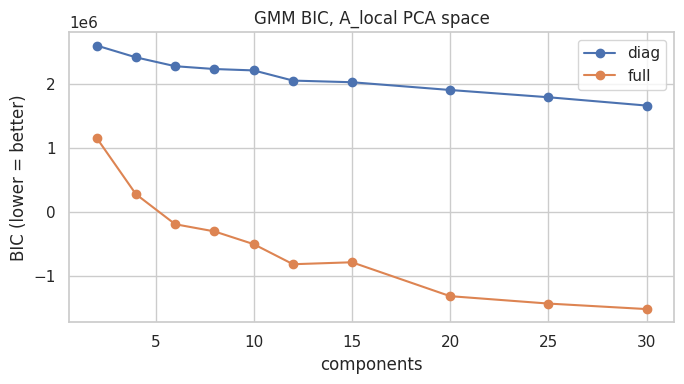


Chosen: covariance=full, k=30
Converged: True
         n_unknown  n_licit  n_illicit  n_total  n_labelled  illicit_rate   lift
cluster                                                                         
0             6443      925       2197     9565        3122         0.704  6.077
15            6678      657        353     7688        1010         0.350  3.018
13            7957      321        143     8421         464         0.308  2.661
6             4347       52         16     4415          68         0.235  2.032
25            4017      202         62     4281         264         0.235  2.028
12           17032      447        129    17608         576         0.224  1.934
26            3149      594        103     3846         697         0.148  1.276
11            3362      254         27     3643         281         0.096  0.830
19            3766      205         21     3992         226         0.093  0.802
14            5819      893         61     6773         954   

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # we record converged_ instead

# Helper: how much of the later result rests on the single best cluster?
def later_lift_without_top(labels, chosen):
    if not chosen:
        return {}
    y = df["label"].values
    la = (~train_mask) & (y != -1)
    base = (y[la] == 1).mean()
    ill = {c: int(((labels == c) & la & (y == 1)).sum()) for c in chosen}
    top = max(ill, key=ill.get)
    rest = [c for c in chosen if c != top]
    m = la & np.isin(labels, rest)
    return {"top_cluster": top,
            "top_share_of_chosen_illicit": round(ill[top] / max(sum(ill.values()), 1), 3),
            "lift_without_top": round((y[m] == 1).mean() / base, 2) if m.any() else np.nan}

# Sanity check: should reproduce my hand numbers (top=28, share ~0.88, lift ~1.5)
print("HDBSCAN:", later_lift_without_top(hdb_labels, [10, 19, 20, 25, 28, 29]))
print("KMeans A:", later_lift_without_top(km_labels["A_local"], [4, 5]))

# (a) BIC sweep on a fixed 40k training subsample
X = X_pca["A_local"]
sub_g = np.random.default_rng(SEED).choice(np.where(train_mask)[0], 40_000, replace=False)
K_GRID_G = [2, 4, 6, 8, 10, 12, 15, 20, 25, 30]
rows = []
for cov in ["diag", "full"]:
    for k in K_GRID_G:
        t0 = time.time()
        gm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-4,
                             max_iter=100, n_init=1, random_state=SEED).fit(X[sub_g])
        rows.append({"cov": cov, "k": k, "bic": gm.bic(X[sub_g]),
                     "converged": gm.converged_, "secs": round(time.time() - t0)})
bic = pd.DataFrame(rows)
print(bic.pivot(index="k", columns="cov", values="bic").round(0))
print(bic.pivot(index="k", columns="cov", values="converged"))

plt.figure(figsize=(7, 4))
for cov, g in bic.groupby("cov"):
    plt.plot(g["k"], g["bic"], marker="o", label=cov)
plt.xlabel("components"); plt.ylabel("BIC (lower = better)"); plt.legend()
plt.title("GMM BIC, A_local PCA space"); plt.tight_layout(); plt.show()

# Label-free rule, fixed in advance: best covariance type by lowest BIC; then the smallest k
# whose BIC is within 2% of the full BIC range of that curve from its minimum
best_cov = bic.loc[bic["bic"].idxmin(), "cov"]
b = bic[bic["cov"] == best_cov].set_index("k")["bic"]
K_G = int(b[b <= b.min() + 0.02 * (b.max() - b.min())].index.min())
print(f"\nChosen: covariance={best_cov}, k={K_G}")

# (b) Final fit on all training rows, assign every row
gm = GaussianMixture(n_components=K_G, covariance_type=best_cov, reg_covar=1e-4,
                     max_iter=200, n_init=2, random_state=SEED).fit(X[train_mask])
print("Converged:", gm.converged_)
gmm_labels = gm.predict(X).astype(int)

s, tabs = evaluate(gmm_labels, f"GMM-A_local", show_table=True)
print(s.to_string(index=False))
tt = transfer_test(gmm_labels, "GMM-A_local")
print(pd.DataFrame([tt]).to_string(index=False))
print(later_lift_without_top(gmm_labels, tt["chosen_clusters"]))

mixG = pd.crosstab(gmm_labels, np.where(train_mask, "train", "later"), normalize="columns")
mixG["shift"] = mixG["later"] - mixG["train"]
print("\nShare of rows per cluster:\n", mixG.round(3))

c19

In [ ]:
def transfer_generic(labels, tr_mask, te_mask):
    y = df["label"].values
    tr, te = tr_mask & (y != -1), te_mask & (y != -1)
    base_tr, base_te = (y[tr] == 1).mean(), (y[te] == 1).mean()
    ct = pd.crosstab(labels[tr], y[tr]).reindex(columns=[0, 1], fill_value=0)
    n = ct.sum(axis=1)
    lift = (ct[1] / n) / base_tr
    chosen = lift[(n >= MIN_LAB) & (lift >= MIN_LIFT)].index.tolist()   # same thresholds as before
    out = {"n_chosen": len(chosen), "test_base_rate": round(base_te, 4),
           "test_labelled": int(te.sum())}
    if not chosen:
        return out
    hit = np.isin(labels, chosen)
    h = hit[te]
    out["captured"] = round(((y[te] == 1) & h).sum() / (y[te] == 1).sum(), 3)
    out["covered"] = round(h.mean(), 3)
    out["lift"] = round((y[te][h] == 1).mean() / base_te, 2)
    per = {c: int(((labels == c) & te & (y == 1)).sum()) for c in chosen}
    top = max(per, key=per.get)
    m = te & np.isin(labels, [c for c in chosen if c != top])
    out["top_share"] = round(per[top] / max(sum(per.values()), 1), 2)
    out["lift_wo_top"] = round((y[m] == 1).mean() / base_te, 2) if m.any() else np.nan
    return out

def fit_models(Xp, tr_mask, seed=SEED):
    tr_idx = np.where(tr_mask)[0]
    rng = np.random.default_rng(seed)
    labs = {}
    labs["KMeans"] = KMeans(10, n_init=5, random_state=seed).fit(Xp[tr_mask]).predict(Xp)
    s40 = rng.choice(tr_idx, min(40_000, len(tr_idx)), replace=False)
    gm = GaussianMixture(30, covariance_type="full", reg_covar=1e-4, max_iter=100,
                         random_state=seed).fit(Xp[s40])
    labs["GMM"] = gm.predict(Xp)
    s25 = rng.choice(tr_idx, min(25_000, len(tr_idx)), replace=False)
    h = HDBSCAN(min_cluster_size=200, min_samples=10).fit(Xp[s25])
    cm = h.labels_ != -1
    core, cl = s25[cm], h.labels_[cm]
    nn = NearestNeighbors(n_neighbors=2).fit(Xp[core])
    cap = np.percentile(nn.kneighbors(Xp[core])[0][:, 1], 99)
    d, i = nn.kneighbors(Xp, n_neighbors=1)
    lab = np.where(d[:, 0] <= cap, cl[i[:, 0]], -1).astype(int)
    lab[s25] = h.labels_
    labs["HDBSCAN"] = lab
    return labs

steps = df["time_step"].values
rows = []
for T in [20, 27, 34, 41]:
    trm, tem = steps <= T, (steps > T) & (steps <= T + 7)
    Xraw = df[local_cols].to_numpy(dtype=np.float32)
    prep = make_preprocessor("slog_std").fit(Xraw[trm])
    Xs = prep.transform(Xraw).astype(np.float32)
    pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(Xs[trm])
    Xp = pca.transform(Xs).astype(np.float32)
    t0 = time.time()
    for mname, lab in fit_models(Xp, trm).items():
        r = transfer_generic(lab, trm, tem)
        rows.append({"train_to": T, "test": f"{T+1}-{T+7}", "model": mname,
                     "n_PCs": Xp.shape[1], **r})
    print(f"cutoff {T} done in {round(time.time()-t0)}s")

roll = pd.DataFrame(rows)
print(roll.to_string(index=False))
print(roll.groupby("model")[["lift", "lift_wo_top", "captured", "covered"]].agg(["mean", "min"]).round(2))

cutoff 20 done in 89s
cutoff 27 done in 82s
cutoff 34 done in 64s
cutoff 41 done in 72s
 train_to  test   model  n_PCs  n_chosen  test_base_rate  test_labelled  captured  covered  lift  top_share  lift_wo_top
       20 21-27  KMeans     22         1          0.1137           6034     0.569    0.197  2.89       1.00          NaN
       20 21-27     GMM     22         4          0.1137           6034     0.653    0.184  3.54       0.83         1.99
       20 21-27 HDBSCAN     22         8          0.1137           6034     0.650    0.172  3.77       0.80         1.97
       27 28-34  KMeans     22         1          0.2022           4971     0.613    0.394  1.56       1.00          NaN
       27 28-34     GMM     22         6          0.2022           4971     0.786    0.268  2.93       0.66         2.16
       27 28-34 HDBSCAN     22         7          0.2022           4971     0.592    0.183  3.23       0.85         1.75
       34 35-41  KMeans     22         2          0.0862         

c20

In [ ]:
Xa = X_pca["A_local"]
idx = np.random.default_rng(SEED).choice(np.where(train_mask)[0], 10_000, replace=False)
keep = hdb_labels[idx] != -1            # rows HDBSCAN did not call noise

def internal(X, l):
    return {"n_rows": len(l), "n_clusters": len(set(l)),
            "silhouette": round(silhouette_score(X, l), 3),
            "davies_bouldin": round(davies_bouldin_score(X, l), 3),
            "calinski_harabasz": round(calinski_harabasz_score(X, l), 0)}

models = {"KMeans k=10": km_labels["A_local"],
          "GMM full k=30": gmm_labels,
          "HDBSCAN (200,10)": hdb_labels}
rows = []
for name, lab in models.items():
    l = lab[idx]
    if name.startswith("HDBSCAN"):
        rows.append({"model": name, "rows_used": "non-noise only", **internal(Xa[idx][keep], l[keep])})
    else:
        rows.append({"model": name, "rows_used": "all rows", **internal(Xa[idx], l)})
        rows.append({"model": name, "rows_used": "HDBSCAN non-noise rows",
                     **internal(Xa[idx][keep], l[keep])})
print(pd.DataFrame(rows).to_string(index=False))
print("Share of this sample HDBSCAN calls noise:", round((~keep).mean(), 3))

           model              rows_used  n_rows  n_clusters  silhouette  davies_bouldin  calinski_harabasz
     KMeans k=10               all rows   10000          10       0.163           1.552             1328.0
     KMeans k=10 HDBSCAN non-noise rows    5259           9       0.277           1.047             1734.0
   GMM full k=30               all rows   10000          30       0.027           3.116              353.0
   GMM full k=30 HDBSCAN non-noise rows    5259          26       0.169           2.260              564.0
HDBSCAN (200,10)         non-noise only    5259          30       0.337           1.167              734.0
Share of this sample HDBSCAN calls noise: 0.474


c21

In [ ]:
Z = X_scaled["A_local"]                   # slog_std-scaled local features (fit on steps 1-34)
y = df["label"].values
fn = np.array(local_cols)
chosen = [10, 19, 20, 25, 28, 29]         # selected earlier from steps 1-34 labels

rows = []
for c in chosen + [-1]:
    m = hdb_labels == c
    zc = Z[m].mean(axis=0)
    top = np.argsort(-np.abs(zc))[:5]
    ts = df.loc[m, "time_step"]
    rows.append({"cluster": c, "n": int(m.sum()),
                 "unknown_n": int((y[m] == -1).sum()),
                 "unknown_share": round((y[m] == -1).mean(), 2),
                 "steps_median": int(ts.median()),
                 "steps_IQR": f"{int(ts.quantile(.25))}-{int(ts.quantile(.75))}",
                 "in_deg": round(df.loc[m, "in_degree"].mean(), 2),
                 "out_deg": round(df.loc[m, "out_degree"].mean(), 2),
                 "pagerank": round(df.loc[m, "pagerank"].mean(), 2),
                 "top5_features (mean z)": ", ".join(f"{fn[i]}:{zc[i]:+.1f}" for i in top)})
prof = pd.DataFrame(rows)
print(prof.to_string(index=False))
print("\nWhole-data reference: in_deg 1.15, out_deg 1.15, pagerank 1.00")

 cluster     n  unknown_n  unknown_share  steps_median steps_IQR  in_deg  out_deg  pagerank                           top5_features (mean z)
      10  2108       1957           0.93            11      4-23    0.79     1.03      0.98 f75:-2.1, f74:-2.1, f86:-1.4, f87:-1.4, f80:-1.4
      19  4021       3266           0.81            35     20-42    0.67     1.02      0.69 f86:-1.4, f87:-1.4, f80:-1.4, f81:-1.4, f21:-1.3
      20  5561       5139           0.92            25     13-38    0.74     1.10      0.98 f87:-1.4, f86:-1.4, f81:-1.4, f80:-1.4, f62:-1.3
      25  4634       4290           0.93            36     23-42    0.81     1.18      0.95  f86:-1.4, f87:-1.4, f80:-1.4, f81:-1.4, f3:+1.1
      28  6605       4029           0.61            31     22-40    0.69     0.57      0.59  f3:+1.2, f90:-0.8, f89:-0.7, f91:-0.6, f20:-0.4
      29  5556       4368           0.79            13      9-24    0.79     0.50      0.61  f90:-0.8, f3:-0.8, f89:-0.6, f88:+0.5, f53:-0.4
      -1 8456

ct19

         lift_mean  lift_min  lift_wo_top_mean  captured_mean  covered_mean  precision_mean  silhouette_nonnoise
model                                                                                                           
GMM           2.92      2.51              1.24           0.63          0.22            0.33                 0.17
HDBSCAN       6.39      3.23              1.95           0.64          0.13            0.55                 0.34
KMeans        2.31      1.56              0.00           0.66          0.30            0.24                 0.28


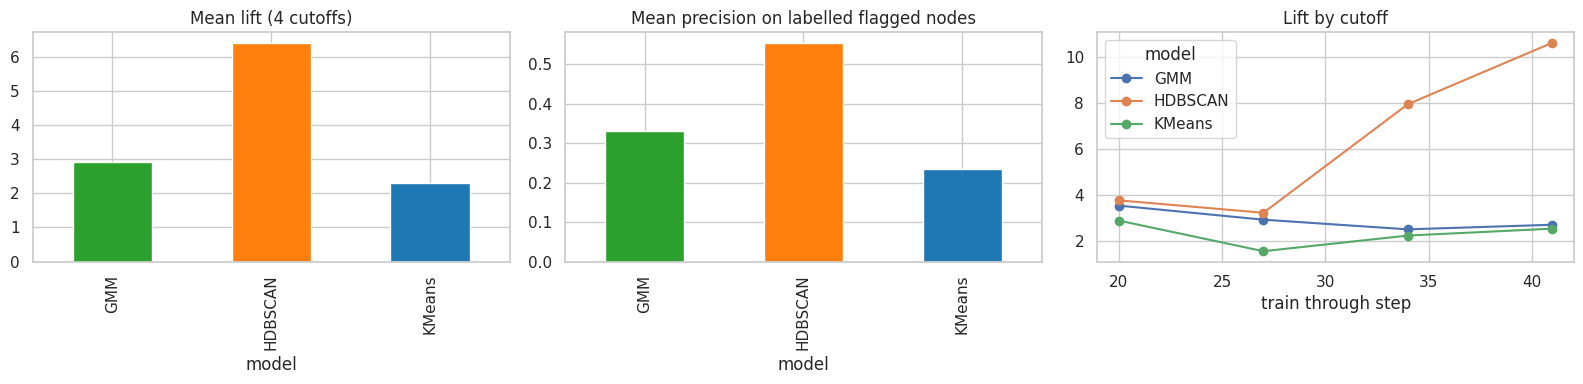

In [ ]:
cmp = roll.groupby("model").agg(
    lift_mean=("lift", "mean"), lift_min=("lift", "min"),
    lift_wo_top_mean=("lift_wo_top", "mean"),
    captured_mean=("captured", "mean"), covered_mean=("covered", "mean"))
cmp["precision_mean"] = (roll.assign(p=roll["lift"] * roll["test_base_rate"])
                              .groupby("model")["p"].mean())
cmp["silhouette_nonnoise"] = pd.Series({"KMeans": 0.277, "GMM": 0.169, "HDBSCAN": 0.337})
print(cmp.round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cmp["lift_mean"].plot(kind="bar", ax=ax[0], color=["tab:green", "tab:orange", "tab:blue"])
ax[0].set_title("Mean lift (4 cutoffs)")
cmp["precision_mean"].plot(kind="bar", ax=ax[1], color=["tab:green", "tab:orange", "tab:blue"])
ax[1].set_title("Mean precision on labelled flagged nodes")
roll.pivot(index="train_to", columns="model", values="lift").plot(marker="o", ax=ax[2])
ax[2].set_title("Lift by cutoff"); ax[2].set_xlabel("train through step")
plt.tight_layout(); plt.show()

ct20

In [ ]:
# Training-period evidence and later-period evidence for each cluster
tr = train_mask & (y != -1); la = (~train_mask) & (y != -1)
def stats(c, m):
    lm = m & (hdb_labels == c)
    return int(lm.sum()), (y[lm] == 1).mean() if lm.any() else np.nan

rows = []
for c in chosen:
    nt, rt = stats(c, tr); nl, rl = stats(c, la)
    rows.append({"cluster": c, "train_labelled": nt, "train_rate": round(rt, 3),
                 "later_labelled": nl, "later_rate": round(rl, 3),
                 "unknown_nodes": int(((hdb_labels == c) & (y == -1)).sum())})
rank = pd.DataFrame(rows)
rank["tier"] = np.where((rank["later_labelled"] >= 100) & (rank["later_rate"] >= 0.13), "A: held up",
                np.where(rank["later_rate"] >= 0.13, "B: held, thin evidence", "C: did not hold"))
print(rank.sort_values("later_rate", ascending=False).to_string(index=False))

# Flag unlabelled nodes, tier A clusters only, steps after 34 (never used to choose clusters)
tierA = rank.loc[rank["tier"].str.startswith("A"), "cluster"].tolist()
flag = df[(hdb_labels != -1) & np.isin(hdb_labels, tierA) & (y == -1) & (~train_mask)][["txId", "time_step"]]
flag = flag.assign(cluster=hdb_labels[flag.index])
print("Tier A clusters:", tierA, "| unlabelled nodes flagged:", len(flag))
flag.to_csv("flagged_unlabelled_nodes.csv", index=False)

 cluster  train_labelled  train_rate  later_labelled  later_rate  unknown_nodes                   tier
      28            1885       0.640             691       0.964           4029             A: held up
      20             202       0.356             220       0.191           5139             A: held up
      29            1134       0.883              54       0.167           4368 B: held, thin evidence
      19             363       0.242             392       0.079           3266        C: did not hold
      10             119       0.277              32       0.062           1957        C: did not hold
      25             113       0.274             231       0.039           4290        C: did not hold
Tier A clusters: [20, 28] | unlabelled nodes flagged: 3582


c22

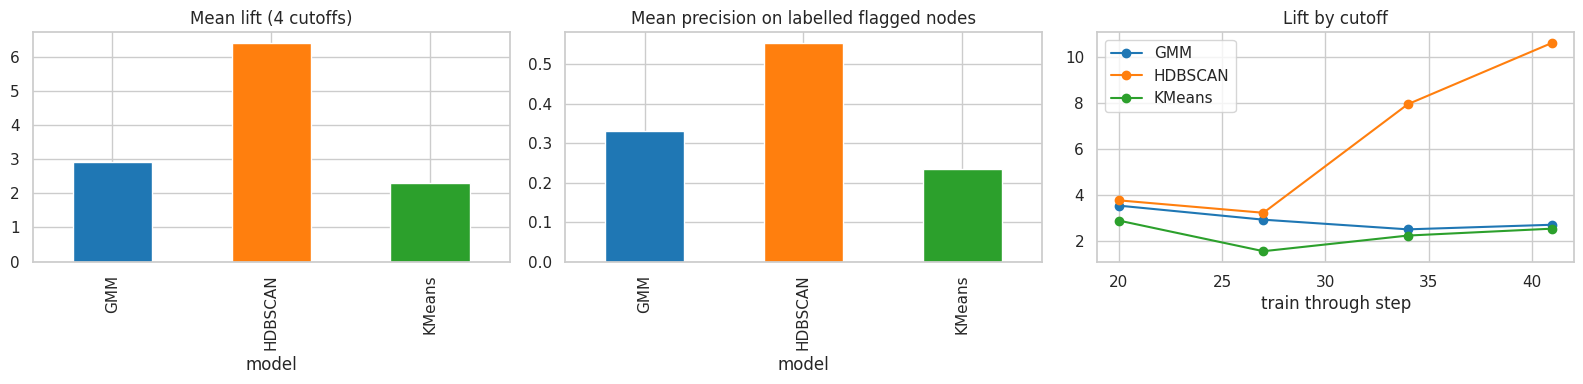

priority
high      1886
medium    1696
Name: count, dtype: int64


In [ ]:
# (a) Corrected CT-19 chart: one fixed colour per model across all panels
COL = {"GMM": "tab:blue", "HDBSCAN": "tab:orange", "KMeans": "tab:green"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, title in [(ax[0], "lift_mean", "Mean lift (4 cutoffs)"),
                      (ax[1], "precision_mean", "Mean precision on labelled flagged nodes")]:
    cmp[col].plot(kind="bar", ax=a, color=[COL[m] for m in cmp.index]); a.set_title(title)
lift_piv = roll.pivot(index="train_to", columns="model", values="lift")
for m in lift_piv.columns:
    ax[2].plot(lift_piv.index, lift_piv[m], marker="o", color=COL[m], label=m)
ax[2].set_title("Lift by cutoff"); ax[2].set_xlabel("train through step"); ax[2].legend()
plt.tight_layout(); plt.show()

# (b) Add a priority column to the flag list so the strong and weak cluster are separable
flag["priority"] = np.where(flag["cluster"] == 28, "high", "medium")
flag.to_csv("flagged_unlabelled_nodes.csv", index=False)
print(flag["priority"].value_counts())

c23

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


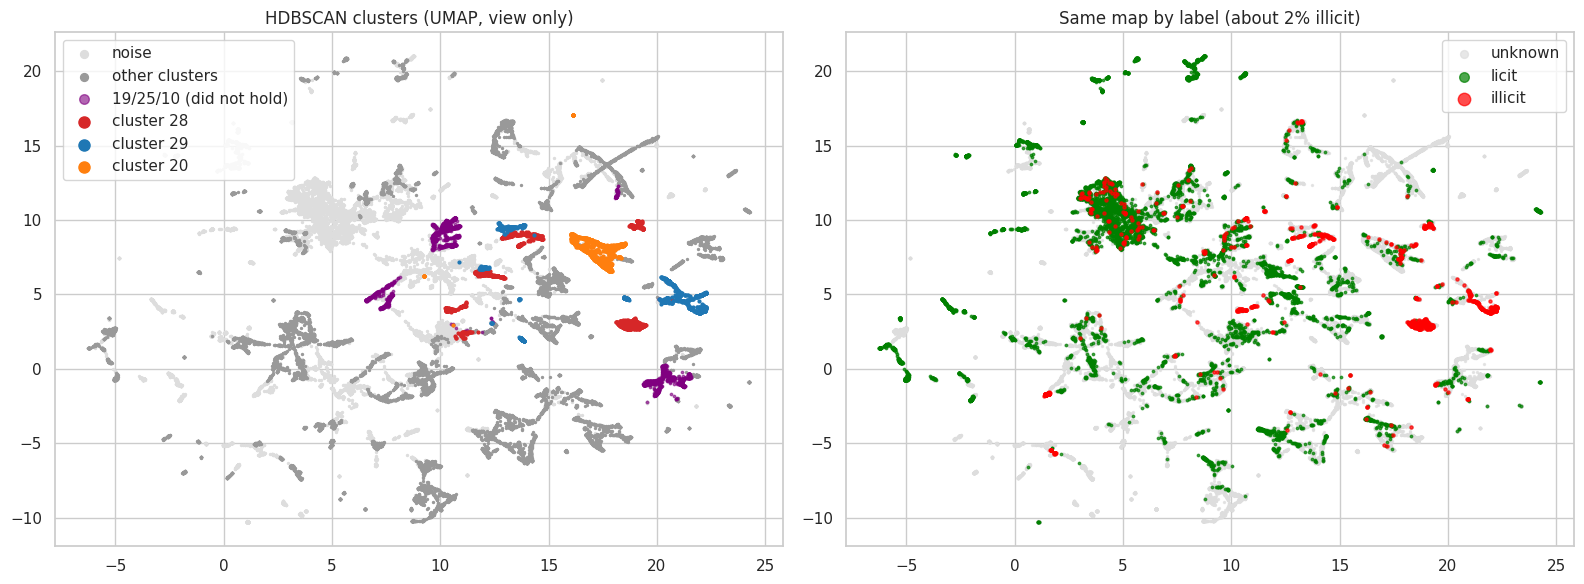

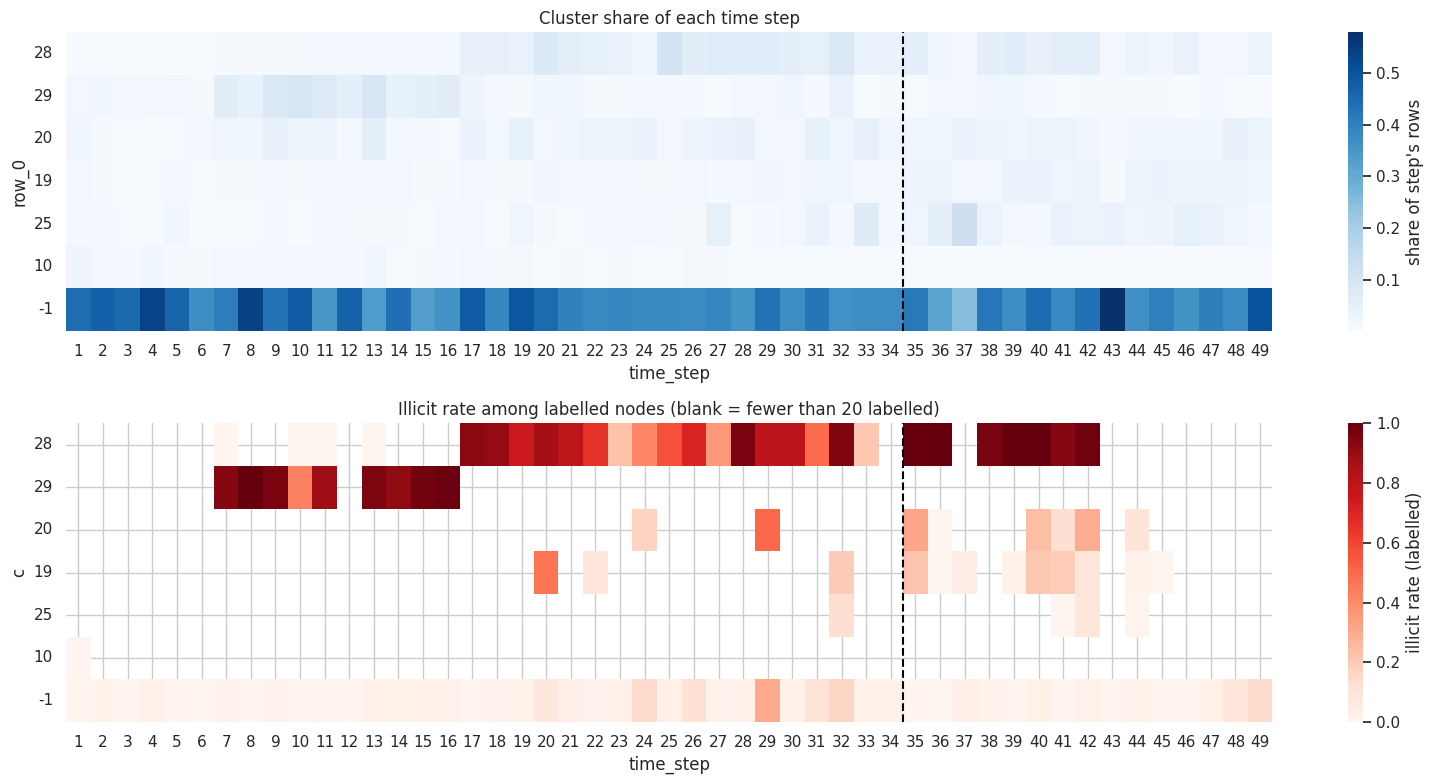

step 42: 395 cluster-28 nodes, 734 nodes shown, 549 edges


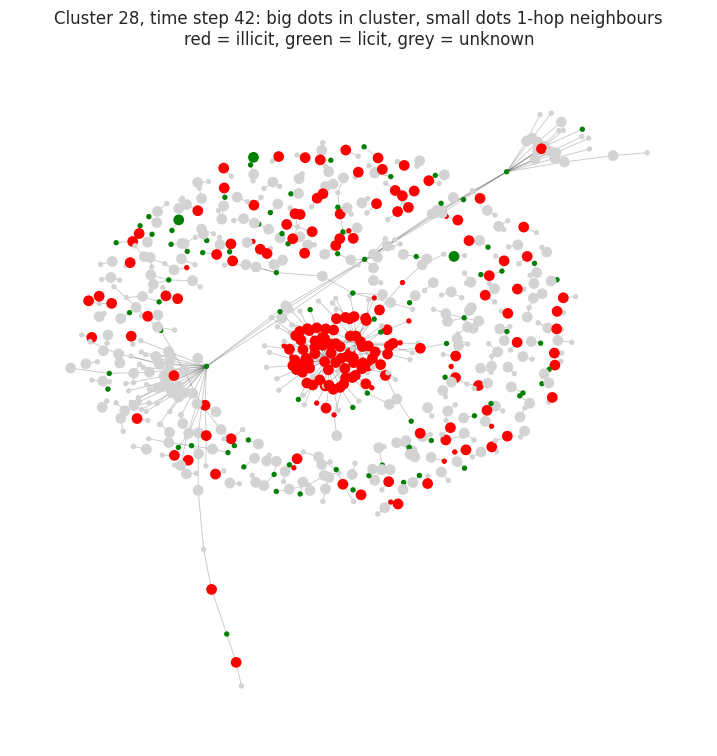

In [ ]:
import umap, seaborn as sns
HL = {28: "tab:red", 29: "tab:blue", 20: "tab:orange"}
WEAK = [19, 25, 10]

# (a) UMAP of a UNIFORM random 40k sample (no over-sampling, so density is honest)
vi = np.random.default_rng(SEED).choice(len(df), 40_000, replace=False)
emb2 = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(X_pca["A_local"][vi])
cl_v, y_v = hdb_labels[vi], y[vi]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
m = cl_v == -1
ax[0].scatter(emb2[m, 0], emb2[m, 1], s=2, c="#dddddd", label="noise")
m = (cl_v != -1) & ~np.isin(cl_v, list(HL) + WEAK)
ax[0].scatter(emb2[m, 0], emb2[m, 1], s=2, c="#999999", label="other clusters")
m = np.isin(cl_v, WEAK)
ax[0].scatter(emb2[m, 0], emb2[m, 1], s=3, c="purple", alpha=.6, label="19/25/10 (did not hold)")
for c, col in HL.items():
    m = cl_v == c
    ax[0].scatter(emb2[m, 0], emb2[m, 1], s=4, c=col, label=f"cluster {c}")
ax[0].legend(markerscale=4); ax[0].set_title("HDBSCAN clusters (UMAP, view only)")

for name, col, s in [("unknown", "#dddddd", 2), ("licit", "green", 3), ("illicit", "red", 5)]:
    code = {"unknown": -1, "licit": 0, "illicit": 1}[name]
    m = y_v == code
    ax[1].scatter(emb2[m, 0], emb2[m, 1], s=s, c=col, label=name, alpha=.7)
ax[1].legend(markerscale=4); ax[1].set_title("Same map by label (about 2% illicit)")
plt.tight_layout(); plt.show()

# (b) Time-step heatmaps for the flagged clusters
cl_list = [28, 29, 20, 19, 25, 10, -1]
steps_all = np.arange(1, 50)
share = pd.crosstab(hdb_labels, df["time_step"].values, normalize="columns")
share = share.reindex(index=cl_list, columns=steps_all)

d = pd.DataFrame({"c": hdb_labels, "t": df["time_step"].values, "y": y})
d = d[d["y"] != -1]
g = d.groupby(["c", "t"])["y"].agg(["mean", "size"]).reset_index()
rate = g.pivot(index="c", columns="t", values="mean").reindex(index=cl_list, columns=steps_all)
cnt = g.pivot(index="c", columns="t", values="size").reindex(index=cl_list, columns=steps_all)
rate = rate.where(cnt >= 20)          # hide cells with fewer than 20 labelled nodes

fig, ax = plt.subplots(2, 1, figsize=(16, 8))
sns.heatmap(share, ax=ax[0], cmap="Blues", cbar_kws={"label": "share of step's rows"})
ax[0].set_title("Cluster share of each time step")
sns.heatmap(rate, ax=ax[1], cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "illicit rate (labelled)"})
ax[1].set_title("Illicit rate among labelled nodes (blank = fewer than 20 labelled)")
for a in ax:
    a.set_yticklabels([str(c) for c in cl_list], rotation=0)
    a.axvline(34, color="black", ls="--")      # train | later boundary
    a.set_xlabel("time_step")
plt.tight_layout(); plt.show()

# (c) Graph view: cluster 28 in the busiest later time step, plus 1-hop neighbours
import networkx as nx
c = 28
t_pick = df.loc[(hdb_labels == c) & (~train_mask), "time_step"].value_counts().idxmax()
core_ids = set(df.loc[(hdb_labels == c) & (df["time_step"] == t_pick), "txId"])
e_s = edges[edges["src"].isin(core_ids) | edges["dst"].isin(core_ids)]
G = nx.from_pandas_edgelist(e_s, "src", "dst", create_using=nx.DiGraph)
G.add_nodes_from(core_ids)
print(f"step {t_pick}: {len(core_ids)} cluster-{c} nodes, {G.number_of_nodes()} nodes shown, "
      f"{G.number_of_edges()} edges")

lab_map = df.set_index("txId")["label"]
cmap = {1: "red", 0: "green", -1: "lightgray"}
nodes = list(G.nodes())
colors = [cmap[lab_map[n]] for n in nodes]
sizes = [60 if n in core_ids else 15 for n in nodes]
pos = nx.spring_layout(G, seed=SEED, k=0.15)
plt.figure(figsize=(9, 9))
nx.draw_networkx_edges(G, pos, alpha=.25, arrows=False, width=.6)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=colors, node_size=sizes, linewidths=0)
plt.title(f"Cluster {c}, time step {t_pick}: big dots in cluster, small dots 1-hop neighbours\n"
          "red = illicit, green = licit, grey = unknown")
plt.axis("off"); plt.show()

c24

In [ ]:
# Label support for each flagged node's own (cluster, time_step)
lab_df = pd.DataFrame({"cluster": hdb_labels, "time_step": df["time_step"].values, "y": y})
lab_df = lab_df[lab_df["y"] != -1]
ev = (lab_df.groupby(["cluster", "time_step"])["y"]
            .agg(step_rate="mean", step_n="size").reset_index())

fl = flag.drop(columns="priority").merge(ev, on=["cluster", "time_step"], how="left")
fl["step_n"] = fl["step_n"].fillna(0)
fl["support"] = np.where(fl["step_n"] < 20, "no label evidence in this step",
                 np.where(fl["step_rate"] >= 0.13, "step rate >= 0.13", "step rate < 0.13"))
fl["priority"] = np.where(fl["support"] != "step rate >= 0.13", "low",
                  np.where(fl["cluster"] == 28, "high", "medium"))

print(pd.crosstab(fl["cluster"], fl["support"]))
print(fl["priority"].value_counts())
print(fl.groupby("priority")["time_step"].agg(["min", "max", "nunique"]))
fl.to_csv("flagged_unlabelled_nodes.csv", index=False)

support  no label evidence in this step  step rate < 0.13  step rate >= 0.13
cluster                                                                     
20                                  897               398                401
28                                  850                 0               1036
priority
low       2145
high      1036
medium     401
Name: count, dtype: int64
          min  max  nunique
priority                   
high       35   42        7
low        36   49       12
medium     35   42        3


c25

In [ ]:
import torch, torch.nn as nn
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV)

class AE(nn.Module):
    def __init__(self, d_in, d_lat=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(),
                                 nn.Linear(64, 32), nn.ReLU(),
                                 nn.Linear(32, d_lat))
        self.dec = nn.Sequential(nn.Linear(d_lat, 32), nn.ReLU(),
                                 nn.Linear(32, 64), nn.ReLU(),
                                 nn.Linear(64, d_in))
    def forward(self, x):
        return self.dec(self.enc(x))

def train_ae(Xtr, d_lat=16, epochs=40, bs=512, lr=1e-3, seed=SEED, patience=5):
    """Train on training-period rows only; 10% of them held out for early stopping."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(Xtr), generator=g).numpy()
    n_val = len(Xtr) // 10
    Xv = torch.tensor(Xtr[perm[:n_val]]).to(DEV)
    Xf = torch.tensor(Xtr[perm[n_val:]])
    model = AE(Xtr.shape[1], d_lat).to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xf), generator=g)
        for s in range(0, len(Xf), bs):
            xb = Xf[order[s:s + bs]].to(DEV)
            loss = ((model(xb) - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(Xv) - Xv) ** 2).mean().item()
        if v < best - 1e-5:
            best, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, best, ep + 1

def embed(model, X, bs=20000):
    out = []
    with torch.no_grad():
        for s in range(0, len(X), bs):
            out.append(model.enc(torch.tensor(X[s:s + bs]).to(DEV)).cpu().numpy())
    return np.vstack(out).astype(np.float32)

def hdbscan_assign(Xp, sub_idx, mcs, ms):
    """Same approach as Cell 16: fit on a subsample, assign other rows by nearest clustered point."""
    h = HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit(Xp[sub_idx])
    cm = h.labels_ != -1
    core, cl = sub_idx[cm], h.labels_[cm]
    nn_ = NearestNeighbors(n_neighbors=2).fit(Xp[core])
    cap = np.percentile(nn_.kneighbors(Xp[core])[0][:, 1], 99)
    d, i = nn_.kneighbors(Xp, n_neighbors=1)
    lab = np.where(d[:, 0] <= cap, cl[i[:, 0]], -1).astype(int)
    lab[sub_idx] = h.labels_
    return lab, h

# (a) Train on steps 1-34 (A_local, slog_std scaled)
Xs = X_scaled["A_local"]
t0 = time.time()
ae, val_mse, n_ep = train_ae(Xs[train_mask])
print(f"AE trained: {n_ep} epochs, best held-out MSE {val_mse:.4f}, {round(time.time()-t0)}s")

# (b) Sanity check: does it reconstruct better than plain PCA with the same 16 dimensions?
pca16 = PCA(n_components=16, random_state=SEED).fit(Xs[train_mask])
def mse_pca(X): return float(((pca16.inverse_transform(pca16.transform(X)) - X) ** 2).mean())
def mse_ae(X):
    tot = 0.0
    with torch.no_grad():
        for s in range(0, len(X), 20000):
            xb = torch.tensor(X[s:s + 20000]).to(DEV)
            tot += ((ae(xb) - xb) ** 2).sum().item()
    return tot / X.size
print(pd.DataFrame([{"period": p, "data variance": round(float(Xs[m].var(axis=0).mean()), 3),
                     "PCA-16 MSE": round(mse_pca(Xs[m]), 4), "AE-16 MSE": round(mse_ae(Xs[m]), 4)}
                    for p, m in PERIODS.items()]).to_string(index=False))

# (c) Embed every row, then run the same label-free HDBSCAN config rule as Cell 16
Z = embed(ae, Xs)
sub = np.random.default_rng(SEED).choice(np.where(train_mask)[0], 25_000, replace=False)
rows = []
for mcs, ms in CONFIGS:
    h = HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit(Z[sub])
    rows.append({"min_cluster_size": mcs, "min_samples": ms,
                 "n_clusters": len(set(h.labels_)) - (1 if -1 in h.labels_ else 0),
                 "noise_share": round((h.labels_ == -1).mean(), 3)})
cfg_ae = pd.DataFrame(rows)
print(cfg_ae.to_string(index=False))
ok = cfg_ae[cfg_ae["n_clusters"].between(5, 30) & (cfg_ae["noise_share"] <= 0.5)]
assert len(ok), "No config meets the rule - paste the table and we'll adjust BEFORE looking at labels"
best = ok.sort_values(["noise_share", "min_cluster_size"], ascending=[True, False]).iloc[0]
MCS, MS = int(best["min_cluster_size"]), int(best["min_samples"])
print("Chosen:", MCS, MS)

# (d) Evaluate on the 35-49 split, same functions as before
ae_hdb, _ = hdbscan_assign(Z, sub, MCS, MS)
print("Noise share, train rows:", round((ae_hdb[train_mask] == -1).mean(), 3),
      "| later rows:", round((ae_hdb[~train_mask] == -1).mean(), 3))
s, _ = evaluate(ae_hdb, "AE+HDBSCAN", show_table=True)
print(s.to_string(index=False))
tt = transfer_test(ae_hdb, "AE+HDBSCAN")
print(pd.DataFrame([tt]).to_string(index=False))
print(later_lift_without_top(ae_hdb, tt["chosen_clusters"]))

device: cpu
AE trained: 40 epochs, best held-out MSE 0.0194, 56s
       period  data variance  PCA-16 MSE  AE-16 MSE
 train (1-34)          0.743      0.0787     0.0199
later (35-49)          0.654      0.1020     0.0357
 min_cluster_size  min_samples  n_clusters  noise_share
              100           10          48        0.512
              200           10          27        0.496
              400           20          14        0.575
Chosen: 200 10
Noise share, train rows: 0.35 | later rows: 0.316
         n_unknown  n_licit  n_illicit  n_total  n_labelled  illicit_rate   lift
cluster                                                                         
26            3264      165       1018     4447        1183         0.861  7.431
25            1819      813       1133     3765        1946         0.582  5.027
17            3433      147         85     3665         232         0.366  3.164
20            1902      100         32     2034         132         0.242  2.093
14  

c26

In [ ]:
rows = []
for T in [20, 27, 34, 41]:
    trm, tem = steps <= T, (steps > T) & (steps <= T + 7)
    Xraw = df[local_cols].to_numpy(dtype=np.float32)
    prep = make_preprocessor("slog_std").fit(Xraw[trm])             # refit per cutoff, as in Cell 19
    Xs_T = prep.transform(Xraw).astype(np.float32)
    ae_T, vm, ne = train_ae(Xs_T[trm])
    Z_T = embed(ae_T, Xs_T)
    tr_idx = np.where(trm)[0]
    s25 = np.random.default_rng(SEED).choice(tr_idx, min(25_000, len(tr_idx)), replace=False)
    labs = {"AE+HDBSCAN": hdbscan_assign(Z_T, s25, MCS, MS)[0],
            "AE+KMeans": KMeans(10, n_init=5, random_state=SEED).fit(Z_T[trm]).predict(Z_T)}
    for mname, lab in labs.items():
        rows.append({"train_to": T, "test": f"{T+1}-{T+7}", "model": mname,
                     **transfer_generic(lab, trm, tem)})
    print(f"cutoff {T} done (AE epochs {ne}, held-out MSE {vm:.4f})")

roll_ae = pd.DataFrame(rows)
allr = pd.concat([roll.drop(columns="n_PCs"), roll_ae], ignore_index=True)
allr["precision"] = allr["lift"] * allr["test_base_rate"]
for col in ["n_chosen", "lift", "precision", "lift_wo_top"]:
    print(f"\n{col} by cutoff")
    print(allr.pivot(index="train_to", columns="model", values=col).round(2))
print("\nMeans over cutoffs")
print(allr.groupby("model")[["lift", "precision", "lift_wo_top", "captured", "covered"]].mean().round(2))

cutoff 20 done (AE epochs 40, held-out MSE 0.0234)
cutoff 27 done (AE epochs 40, held-out MSE 0.0203)
cutoff 34 done (AE epochs 40, held-out MSE 0.0194)
cutoff 41 done (AE epochs 40, held-out MSE 0.0177)

n_chosen by cutoff
model     AE+HDBSCAN  AE+KMeans  GMM  HDBSCAN  KMeans
train_to                                             
20                 5          1    4        8       1
27                 5          2    6        7       1
34                 4          2    5        6       2
41                 4          1    3        4       1

lift by cutoff
model     AE+HDBSCAN  AE+KMeans   GMM  HDBSCAN  KMeans
train_to                                              
20              3.72       2.63  3.54     3.77    2.89
27              2.45       1.42  2.93     3.23    1.56
34              7.62       1.71  2.51     7.95    2.24
41             11.81       1.57  2.71    10.62    2.54

precision by cutoff
model     AE+HDBSCAN  AE+KMeans   GMM  HDBSCAN  KMeans
train_to                      

In [ ]:
y = df["label"].values
for a in [25, 26]:
    ma = ae_hdb == a
    print(f"AE cluster {a} ({ma.sum()} rows): share by PCA-HDBSCAN cluster")
    print(pd.Series(hdb_labels[ma]).value_counts(normalize=True).head(4).round(3).to_string(), "\n")

rows = []
for c in [26, 25, 17, 20]:
    for pname, pm in PERIODS.items():
        lm = pm & (ae_hdb == c) & (y != -1)
        rows.append({"AE cluster": c, "period": pname, "n_labelled": int(lm.sum()),
                     "illicit_rate": round((y[lm] == 1).mean(), 3) if lm.any() else np.nan})
print(pd.DataFrame(rows).sort_values(["AE cluster", "period"]).to_string(index=False))

AE cluster 25 (6251 rows): share by PCA-HDBSCAN cluster
 28    0.907
-1     0.086
 29    0.004
 18    0.002 

AE cluster 26 (5475 rows): share by PCA-HDBSCAN cluster
 29    0.876
 28    0.091
-1     0.029
 18    0.001 

 AE cluster        period  n_labelled  illicit_rate
         17 later (35-49)         231         0.190
         17  train (1-34)         232         0.366
         20 later (35-49)         255         0.039
         20  train (1-34)         132         0.242
         25 later (35-49)         826         0.735
         25  train (1-34)        1946         0.582
         26 later (35-49)         104         0.481
         26  train (1-34)        1183         0.861


c27

In [ ]:
y = df["label"].values
steps = df["time_step"].values

def chosen_hit(labels, trm):
    """Rows in clusters selected on TRAINING labels only (same thresholds as before)."""
    tr = trm & (y != -1)
    base = (y[tr] == 1).mean()
    ct = pd.crosstab(labels[tr], y[tr]).reindex(columns=[0, 1], fill_value=0)
    n = ct.sum(axis=1)
    lift = (ct[1] / n) / base
    chosen = lift[(n >= MIN_LAB) & (lift >= MIN_LIFT)].index.tolist()
    return np.isin(labels, chosen)

def score_hit(hit, tem):
    te = tem & (y != -1)
    h = hit[te]
    if not h.any():
        return {"flagged_labelled": 0, "captured": 0.0, "covered": 0.0,
                "precision": np.nan, "lift": np.nan}
    base = (y[te] == 1).mean()
    prec = (y[te][h] == 1).mean()
    return {"flagged_labelled": int(h.sum()),
            "captured": round(((y[te] == 1) & h).sum() / (y[te] == 1).sum(), 3),
            "covered": round(h.mean(), 3),
            "precision": round(prec, 3), "lift": round(prec / base, 2)}

Xraw = df[local_cols].to_numpy(dtype=np.float32)
rows = []
for T in [20, 27, 34, 41]:
    trm, tem = steps <= T, (steps > T) & (steps <= T + 7)
    prep = make_preprocessor("slog_std").fit(Xraw[trm])
    Xs_T = prep.transform(Xraw).astype(np.float32)
    tr_idx = np.where(trm)[0]

    # PCA + HDBSCAN: same random draws as Cell 19 (a 40k draw for the GMM comes first, then the 25k)
    pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(Xs_T[trm])
    Xp = pca.transform(Xs_T).astype(np.float32)
    rng = np.random.default_rng(SEED)
    rng.choice(tr_idx, min(40_000, len(tr_idx)), replace=False)
    s25_p = rng.choice(tr_idx, min(25_000, len(tr_idx)), replace=False)
    lab_p, _ = hdbscan_assign(Xp, s25_p, 200, 10)

    # AE + HDBSCAN: same as Cell 26
    ae_T, _, _ = train_ae(Xs_T[trm])
    Z_T = embed(ae_T, Xs_T)
    s25_a = np.random.default_rng(SEED).choice(tr_idx, min(25_000, len(tr_idx)), replace=False)
    lab_a, _ = hdbscan_assign(Z_T, s25_a, MCS, MS)

    hp, ha = chosen_hit(lab_p, trm), chosen_hit(lab_a, trm)
    for name, hit in [("PCA+HDBSCAN", hp), ("AE+HDBSCAN", ha),
                      ("consensus (both)", hp & ha), ("either", hp | ha)]:
        rows.append({"train_to": T, "model": name, **score_hit(hit, tem)})
    print(f"cutoff {T} done")

res = pd.DataFrame(rows)
for col in ["lift", "precision", "captured", "covered", "flagged_labelled"]:
    print(f"\n{col}")
    print(res.pivot(index="train_to", columns="model", values=col).round(2))
print("\nMeans over cutoffs")
print(res.groupby("model")[["lift", "precision", "captured", "covered"]].mean().round(2))

cutoff 20 done
cutoff 27 done
cutoff 34 done
cutoff 41 done

lift
model     AE+HDBSCAN  PCA+HDBSCAN  consensus (both)  either
train_to                                                   
20              3.72         3.77              4.03    3.53
27              2.45         3.23              3.51    2.36
34              7.62         7.95              8.28    7.35
41             11.81        10.62             17.52    8.38

precision
model     AE+HDBSCAN  PCA+HDBSCAN  consensus (both)  either
train_to                                                   
20              0.42         0.43              0.46    0.40
27              0.50         0.65              0.71    0.48
34              0.66         0.68              0.71    0.63
41              0.50         0.45              0.74    0.35

captured
model     AE+HDBSCAN  PCA+HDBSCAN  consensus (both)  either
train_to                                                   
20              0.57         0.65              0.57    0.65
27           

In [ ]:
needed = ["df", "X_pca", "train_mask", "hdb_labels", "evaluate", "transfer_test",
          "later_lift_without_top", "HDBSCAN", "NearestNeighbors", "PERIODS",
          "MIN_LAB", "MIN_LIFT", "time", "np", "pd"]
missing = [n for n in needed if n not in globals()]
print("Missing:", missing or "none")

Missing: none


In [ ]:
from sklearn.metrics import adjusted_rand_score
X = X_pca["A_local"]
tr_idx = np.where(train_mask)[0]

# Tried in this order, stop at the first that passes the label-free rule
full = None
for mcs, ms in [(1000, 10), (500, 10), (2000, 20)]:
    t0 = time.time()
    h = HDBSCAN(min_cluster_size=mcs, min_samples=ms, n_jobs=-1).fit(X[tr_idx])
    n_cl = len(set(h.labels_)) - (1 if -1 in h.labels_ else 0)
    noise = (h.labels_ == -1).mean()
    print(f"mcs={mcs}, ms={ms}: {n_cl} clusters, noise {noise:.3f}, {round(time.time()-t0)}s")
    if 5 <= n_cl <= 30 and noise <= 0.5:
        full = h
        break
assert full is not None, "No config passed the label-free rule - paste the output and we'll adjust before looking at labels"

# Training rows keep HDBSCAN's own labels; steps 35-49 get nearest-clustered-point assignment
core_mask = full.labels_ != -1
core, core_lab = tr_idx[core_mask], full.labels_[core_mask]
nn_ = NearestNeighbors(n_neighbors=2).fit(X[core])
cap = np.percentile(nn_.kneighbors(X[core])[0][:, 1], 99)
later_idx = np.where(~train_mask)[0]
d, i = nn_.kneighbors(X[later_idx], n_neighbors=1)
full_labels = np.full(len(df), -1, dtype=int)
full_labels[tr_idx] = full.labels_
full_labels[later_idx] = np.where(d[:, 0] <= cap, core_lab[i[:, 0]], -1)

print("Noise share, train:", round((full_labels[train_mask] == -1).mean(), 3),
      "| later:", round((full_labels[~train_mask] == -1).mean(), 3))
s, _ = evaluate(full_labels, "HDBSCAN-full", show_table=True)
print(s.to_string(index=False))
tt = transfer_test(full_labels, "HDBSCAN-full")
print(pd.DataFrame([tt]).to_string(index=False))
print(later_lift_without_top(full_labels, tt["chosen_clusters"]))

# How much did subsampling matter? (training rows only)
print("ARI vs the 25k version:", round(adjusted_rand_score(hdb_labels[train_mask], full_labels[train_mask]), 3))
for c in [28, 29]:
    m = hdb_labels == c
    print(f"Old cluster {c} ({m.sum()} rows) -> new clusters:")
    print(pd.Series(full_labels[m]).value_counts(normalize=True).head(3).round(3).to_string())

mcs=1000, ms=10: 37 clusters, noise 0.439, 220s
mcs=500, ms=10: 59 clusters, noise 0.432, 213s
mcs=2000, ms=20: 18 clusters, noise 0.497, 223s
Noise share, train: 0.497 | later: 0.516
         n_unknown  n_licit  n_illicit  n_total  n_labelled  illicit_rate   lift
cluster                                                                         
 17           3478      131       1001     4610        1132         0.884  7.636
 16           1922      570       1198     3690        1768         0.678  5.851
 8            3124       82         58     3264         140         0.414  3.577
 13           5713      118         46     5877         164         0.280  2.422
 10           3380      470        104     3954         574         0.181  1.565
 9            3519      212         39     3770         251         0.155  1.342
 3            2439       50          5     2494          55         0.091  0.785
 15           2725      147         12     2884         159         0.075  0.652
 1    

In [ ]:
h = roll[roll["model"] == "HDBSCAN"].copy()
h["precision"] = h["lift"] * h["test_base_rate"]
final = pd.DataFrame({
    "Metric": ["Mean lift", "Lift without strongest cluster", "Mean precision",
               "Mean captured", "Mean coverage", "Unlabelled nodes flagged"],
    "HDBSCAN (primary)": [round(h["lift"].mean(), 2), round(h["lift_wo_top"].mean(), 2),
                          round(h["precision"].mean(), 2), round(h["captured"].mean(), 2),
                          round(h["covered"].mean(), 2), len(flag)]})
print(final.to_string(index=False))

                        Metric  HDBSCAN (primary)
                     Mean lift               6.39
Lift without strongest cluster               1.95
                Mean precision               0.55
                 Mean captured               0.64
                 Mean coverage               0.13
      Unlabelled nodes flagged            3582.00
